# 08 · Crew generator: build the simulated crew from real data

**Questions**
1. Which statistics of the real datasets does the generator copy, and does the generated crew actually have them?
2. Where exactly are the 4 planted test cases, and what was changed for each?

**Inputs (real):** `pmdata_daily.parquet`, `pmdata_hourly_hr.parquet` (body), `iss_cabin.parquet` (cabin CO2), `msl_rad_hourly.parquet` (radiation).
**Outputs:** `data/demo/` (`telemetry.csv`, `daily.csv`, `crew.json`, `sources.json`) replacing the purely simulated v0 crew (kept in `data/demo_v0/`),
`data/demo/planted_cases.json` (ground truth, **for evaluation only**), figures `reports/figures/08_*.png`.

**Hard rule:** the astronaut is fictional and **simulated**. Real data sets its statistics; only the radiation series is a replay of real measurements
(Curiosity's RAD on Mars, not an astronaut's dosimeter). Every signal's origin is written to `sources.json` and shown in the app.

**Team decisions applied (confirmed in chat on 13 Nov 2026):** the 4 planted cases as proposed; cabin CO2 from a recent ISS mission (RR-23)
with one real high-CO2 stretch of an early mission (RR-1) planted; solar storm = replay of the real May 2024 storm.

In [1]:
import sys
sys.path.insert(0, "../ml")
import json
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sol_ml.nbutil import *
from sol_ml.sim import crew
from sol_ml.detectors import cabin as gate
from sol_ml.detectors import radiation as rad

rng = setup()
pd.set_option("display.width", 230); pd.set_option("display.max_columns", 30)
warnings.filterwarnings("ignore")

pm = pd.read_parquet(PROCESSED / "pmdata_daily.parquet")
pm = pm[~pm.person.isin(crew.EXCLUDED_PEOPLE)]
pm_hourly = pd.read_parquet(PROCESSED / "pmdata_hourly_hr.parquet")
params = crew.fit_body_params(pm, pm_hourly)

## 1. What the generator copies from PMData

In [2]:
fitted = pd.DataFrame({k: {m: v for m, v in params[k].items() if m != "residuals"} for k in ("resting_hr", "sleep_minutes")}).T
print("hourly heart-rate noise (night hours): SD %.1f bpm | donors per self-report: %s" % (
    params["hr_noise_sd"], {r: len(params["reports"][r]) for r in crew.REPORTS}))
print("resting HR is an AR(1) process (phi = day-to-day memory); sleep resamples %d real standardized nights;" % len(params["sleep_minutes"]["residuals"]))
print("each self-report follows the day-to-day transition matrix of one randomly chosen real person.")
fitted.round(2)

hourly heart-rate noise (night hours): SD 6.9 bpm | donors per self-report: {'fatigue': 14, 'mood': 14, 'stress': 14}
resting HR is an AR(1) process (phi = day-to-day memory); sleep resamples 1822 real standardized nights;
each self-report follows the day-to-day transition matrix of one randomly chosen real person.


,mean,between_sd,within_sd,phi
resting_hr,59.17,6.83,2.11,0.85
sleep_minutes,407.50,33.95,66.23,NaN


## 2. Does a generated population look like the real one?
200 simulated people of 150 days each (the length of PMData) are compared with the 14 real people.

In [3]:
sim = pd.concat([crew.gen_daily(params, 150, np.random.default_rng(SEED + i)).assign(person=f"s{i:03d}") for i in range(200)], ignore_index=True)

def describe(df, col):
    g = df.groupby("person")[col]
    return {"mean of personal medians": g.median().mean(), "SD between people": g.median().std(), "SD within a person (median)": g.std().median(),
            "lag-1 autocorrelation (median)": g.apply(lambda s: s.autocorr(1)).median()}

rows = []
for col in ["resting_hr", "sleep_minutes"] + crew.REPORTS:
    real, gen = describe(pm, col), describe(sim, col)
    ks = stats.ks_2samp(pm[col].dropna() - pm.groupby("person")[col].transform("median")[pm[col].notna()],
                        sim[col] - sim.groupby("person")[col].transform("median")).statistic
    for k in real:
        rows.append({"signal": col, "statistic": k, "real PMData": real[k], "generated": gen[k]})
    rows.append({"signal": col, "statistic": "KS distance of the within-person distribution", "real PMData": 0.0, "generated": ks})
compare = pd.DataFrame(rows).set_index(["signal", "statistic"]).round(2)
compare

real PMData  generated
signal        statistic                                                            
resting_hr    mean of personal medians                             59.17      59.39
              SD between people                                     6.83       6.71
              SD within a person (median)                           2.11       1.98
              lag-1 autocorrelation (median)                        0.85       0.83
              KS distance of the within-person distribution         0.00       0.05
sleep_minutes mean of personal medians                            407.50     408.22
              SD between people                                    33.95      35.32
              SD within a person (median)                          66.23      64.18
              lag-1 autocorrelation (median)                        0.03      -0.01
              KS distance of the within-person distribution         0.00       0.03
fatigue       mean of personal medians                              2.86       2.90
              SD between people                                     0.36       0.30
              SD within a person (median)                           0.60       0.61
              lag-1 autocorrelation (median)                        0.13       0.11
              KS distance of the within-person distribution         0.00       0.01
mood          mean of personal medians                              3.14       3.17
              SD between people                                     0.36       0.38
              SD within a person (median)                           0.53       0.59
              lag-1 autocorrelation (median)                        0.16       0.10
              KS distance of the within-person distribution         0.00       0.03
stress        mean of personal medians                              3.00       3.05
              SD between people                                     0.39       0.33
              SD within a person (median)                           0.67       0.72
              lag-1 autocorrelation (median)                        0.30       0.25
              KS distance of the within-person distribution         0.00       0.02

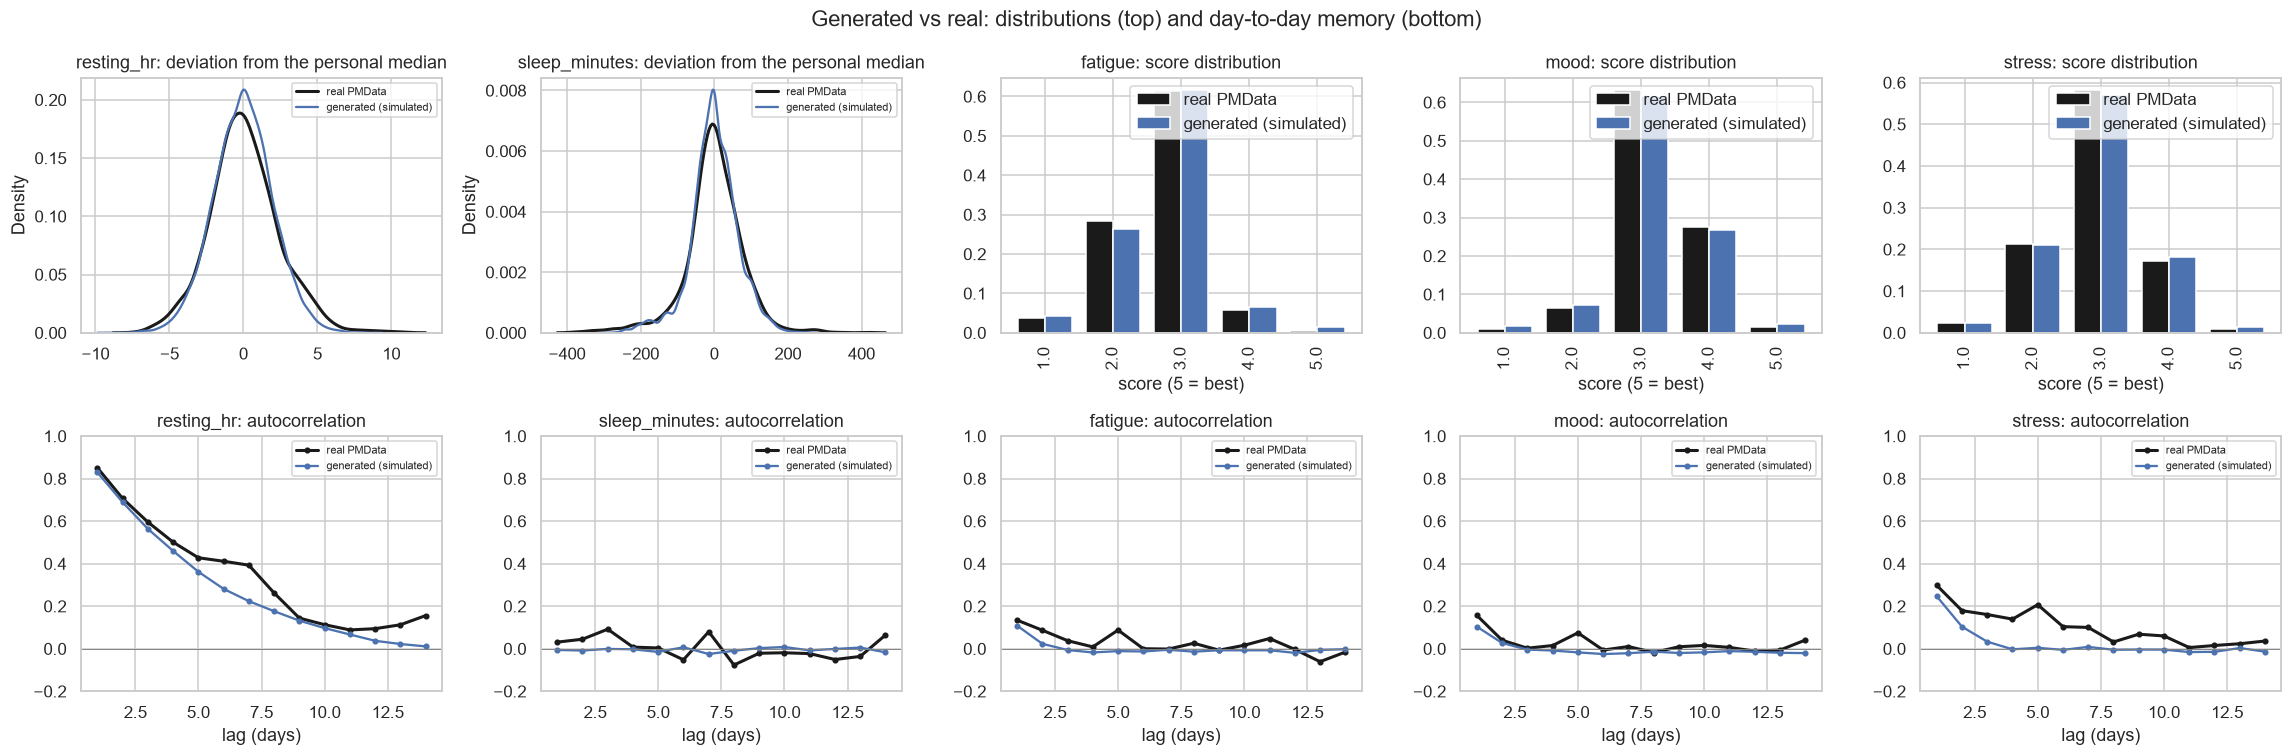

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(21, 7))
for j, col in enumerate(["resting_hr", "sleep_minutes"] + crew.REPORTS):
    r = (pm[col] - pm.groupby("person")[col].transform("median")).dropna()
    g = sim[col] - sim.groupby("person")[col].transform("median")
    ax = axes[0, j]
    if col in crew.REPORTS:
        both = pd.DataFrame({"real PMData": pm[col].value_counts(normalize=True), "generated (simulated)": sim[col].value_counts(normalize=True)}).sort_index()
        both.plot.bar(ax=ax, color=["k", "#4c72b0"], width=0.8); ax.set(title=f"{col}: score distribution", xlabel="score (5 = best)")
    else:
        sns.kdeplot(r, ax=ax, color="k", lw=2, label="real PMData"); sns.kdeplot(g, ax=ax, color="#4c72b0", label="generated (simulated)")
        ax.set(title=f"{col}: deviation from the personal median", xlabel=""); ax.legend(fontsize=7)
    ax = axes[1, j]
    def acf_curve(df):
        return np.nanmedian([[s.autocorr(k) for k in range(1, 15)] for _, s in df.groupby("person")[col] if s.notna().sum() > 60], axis=0)
    ax.plot(range(1, 15), acf_curve(pm), color="k", lw=2, marker="o", ms=3, label="real PMData")
    ax.plot(range(1, 15), acf_curve(sim), color="#4c72b0", marker="o", ms=3, label="generated (simulated)")
    ax.axhline(0, color="grey", lw=0.6); ax.set(title=f"{col}: autocorrelation", xlabel="lag (days)", ylim=(-0.2, 1)); ax.legend(fontsize=7)
fig.suptitle("Generated vs real: distributions (top) and day-to-day memory (bottom)")
savefig("08_generated_vs_real_body");

## 3. Build the demo astronaut and plant the 4 cases

In [5]:
demo = crew.build_demo(seed=SEED)
tel, daily, cases = demo["telemetry"], demo["daily"], demo["planted_cases"]
print(len(demo["crew"]), "crew,", len(tel), "hourly rows,", len(daily), "daily rows, mission:", demo["mission"]["name"])
print("radiation replay:", demo["mission"]["radiation_replay"], "| cabin CO2:", demo["mission"]["cabin_co2_source"])
pd.DataFrame(cases)[["id", "astronaut_id", "start", "end", "planted", "expected"]]

1 crew, 1800 hourly rows, 75 daily rows, mission: Sol-1 (fictional solo Mars surface mission)
radiation replay: {'dataset': 'MSL RAD', 'from': '2024-03-07 00:00:00', 'to': '2024-05-20 23:00:00'} | cabin CO2: {'base': 'RR-23 (2020)', 'planted_high': 'RR-1 (2014)'}


,id,astronaut_id,start,end,planted,expected
0,cabin_co2,UH-01,2026-09-23 00:00:00,2026-10-03 00:00:00,the highest real 10-day CO2 stretch of ISS mis...,environmental gate: 7-day CO2 mean above 2.5 m...
1,slow_drift,UH-01,2026-10-09 00:00:00,2026-10-23 23:00:00,"resting HR +6 bpm, sleep -60 min and fatigue o...",CUSUM on the personal z-score of resting HR / ...
2,solar_storm,UH-01,2026-11-13 05:00:00,2026-11-13 23:00:00,replay of the real 20 May 2024 storm measured ...,SPE alarm in the first hour: radiation elevate...
3,optic_disc,UH-01,2026-10-29 09:00:00,2026-11-13 23:00:00,the day-60 fundus photo (synthetic) shows an e...,fundus photo check: margin less sharp than the...
4,odd_combination,UH-01,2026-10-31 00:00:00,2026-11-07 00:00:00,mood and stress one point worse and sleep 55 m...,multivariate model (Isolation Forest on the da...


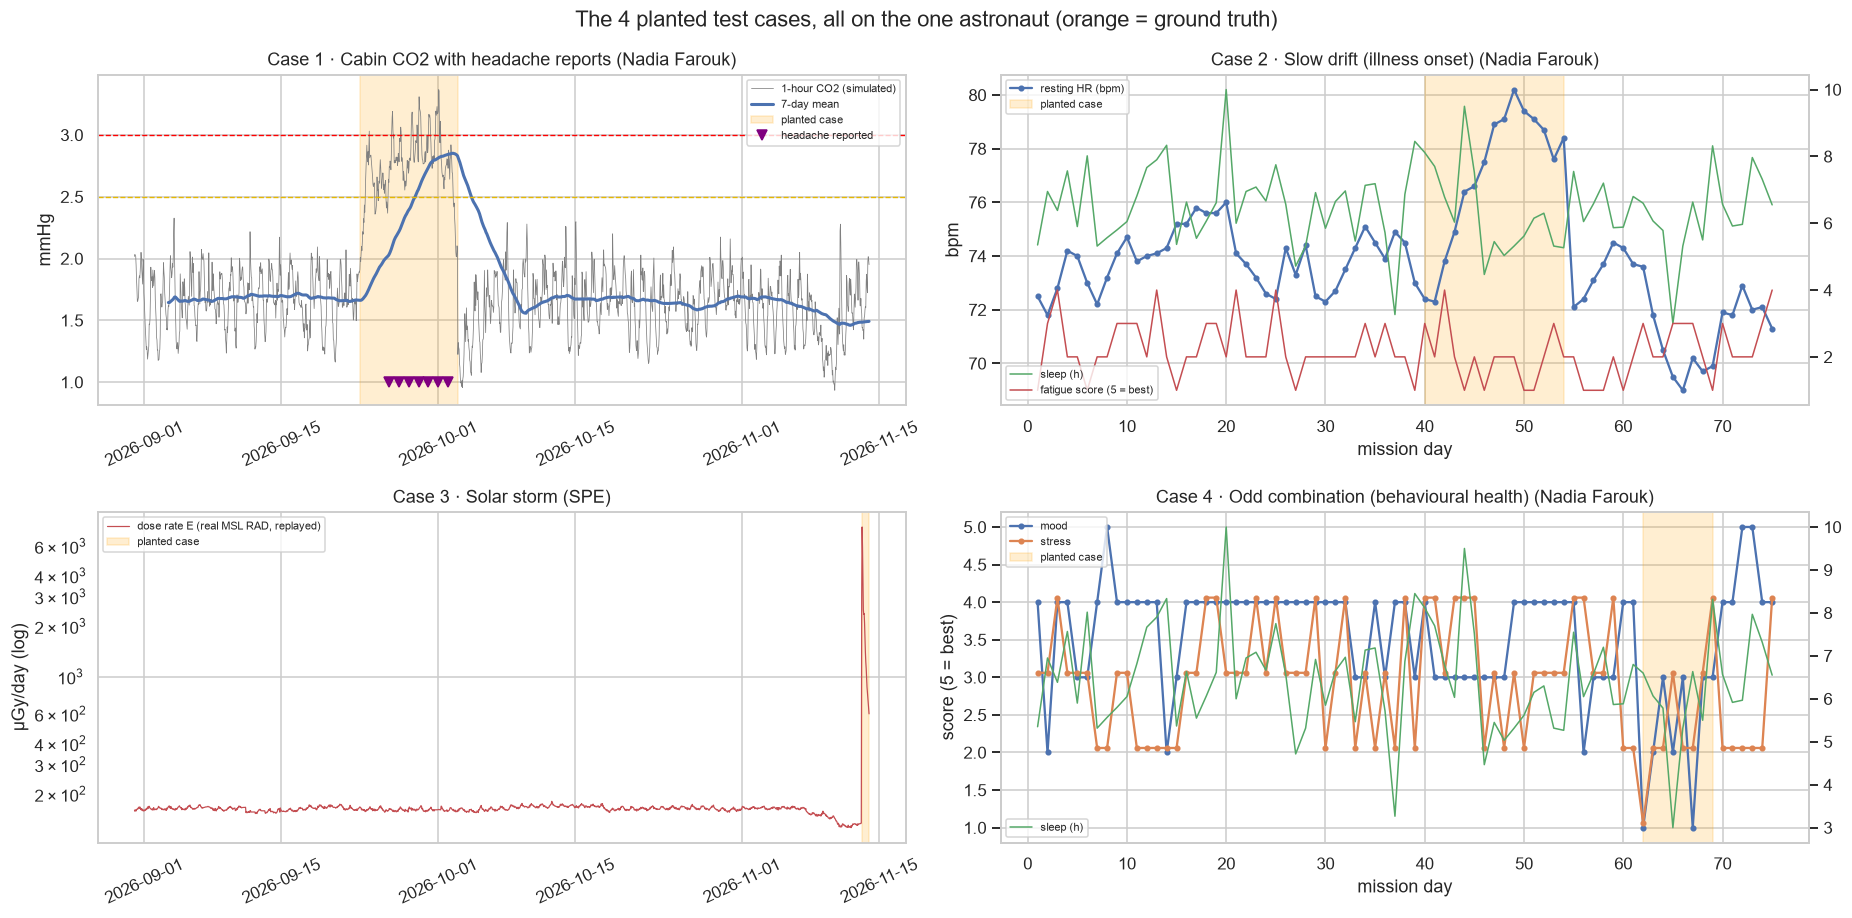

In [6]:
name = {c["astronaut_id"]: c["name"] for c in demo["crew"]}
fig, axes = plt.subplots(2, 2, figsize=(17, 8.5))
case = {c["id"]: c for c in cases}
def shade(ax, c, x):
    lo, hi = pd.Timestamp(c["start"]), pd.Timestamp(c["end"])
    start = pd.Timestamp(demo["mission"]["start"])
    ax.axvspan((lo - start).days + 1 if x == "day" else lo, (hi - start).days + 1 if x == "day" else hi, color="orange", alpha=0.18, label="planted case")

ax = axes[0, 0]; c = case["cabin_co2"]; one = tel[tel.astronaut_id == "UH-01"]
ax.plot(one.timestamp, one.cabin_co2_mmhg, lw=0.5, color="grey", label="1-hour CO2 (simulated)")
ax.plot(one.timestamp, gate.rolling_mean(one.cabin_co2_mmhg.to_numpy()), lw=2, label="7-day mean")
ax.axhline(2.5, color="#e6b800", ls="--", lw=0.9); ax.axhline(3.0, color="red", ls="--", lw=0.9); shade(ax, c, "time")
d = daily[(daily.astronaut_id == "UH-01") & (daily.headache == 1)]
ax.plot(pd.to_datetime(d.date), np.full(len(d), 1.0), "v", color="purple", label="headache reported")
ax.set(title=f"Case 1 · {c['title']} ({name['UH-01']})", ylabel="mmHg"); ax.legend(fontsize=7); ax.tick_params(axis="x", rotation=25)

ax = axes[0, 1]; c = case["slow_drift"]; d = daily[daily.astronaut_id == c["astronaut_id"]]
ax.plot(d.mission_day, d.resting_hr, marker="o", ms=3, label="resting HR (bpm)")
ax2 = ax.twinx(); ax2.plot(d.mission_day, d.sleep_minutes / 60, color="#55a868", lw=1, label="sleep (h)"); ax2.plot(d.mission_day, d.fatigue, color="#c44e52", lw=1, label="fatigue score (5 = best)")
shade(ax, c, "day"); ax.set(title=f"Case 2 · {c['title']} ({name[c['astronaut_id']]})", xlabel="mission day", ylabel="bpm")
ax.legend(loc="upper left", fontsize=7); ax2.legend(loc="lower left", fontsize=7); ax2.grid(False)

ax = axes[1, 0]; c = case["solar_storm"]
ax.plot(one.timestamp, one.radiation_ugy_per_day, lw=0.8, color="#c44e52", label="dose rate E (real MSL RAD, replayed)")
shade(ax, c, "time"); ax.set(yscale="log", title=f"Case 3 · {c['title']}", ylabel="µGy/day (log)"); ax.legend(fontsize=7); ax.tick_params(axis="x", rotation=25)

ax = axes[1, 1]; c = case["odd_combination"]; d = daily[daily.astronaut_id == c["astronaut_id"]]
ax.plot(d.mission_day, d.mood, marker="o", ms=3, label="mood"); ax.plot(d.mission_day, d.stress + 0.06, marker="o", ms=3, label="stress")
ax2 = ax.twinx(); ax2.plot(d.mission_day, d.sleep_minutes / 60, color="#55a868", lw=1, label="sleep (h)"); ax2.grid(False)
shade(ax, c, "day"); ax.set(title=f"Case 4 · {c['title']} ({name[c['astronaut_id']]})", xlabel="mission day", ylabel="score (5 = best)", ylim=(0.8, 5.2))
ax.legend(loc="upper left", fontsize=7); ax2.legend(loc="lower left", fontsize=7)
fig.suptitle("The 4 planted test cases, all on the one astronaut (orange = ground truth)")
savefig("08_planted_cases");

In [7]:
# How big are the planted changes for the people who got them? (in that person's own robust SD before the case)
from sol_ml.detectors.baseline import robust_scale
rows = []
for cid, cols in (("slow_drift", ["resting_hr", "sleep_minutes", "fatigue"]), ("odd_combination", ["mood", "stress", "sleep_minutes"])):
    c = case[cid]; d = daily[daily.astronaut_id == c["astronaut_id"]]
    first = (pd.Timestamp(c["start"]) - pd.Timestamp(demo["mission"]["start"])).days + 1
    before, during = d[d.mission_day.between(first - 28, first - 1)], d[d.mission_day >= first].tail(7)
    for col in cols:
        scale = robust_scale(before[col].to_numpy(), ordinal=col in crew.REPORTS)
        rows.append({"case": cid, "signal": col, "median before": before[col].median(), "median in the last 7 days": during[col].median(),
                     "change in personal robust SD": (during[col].median() - before[col].median()) / scale})
sizes = pd.DataFrame(rows).set_index(["case", "signal"]).round(2)
sizes

median before  median in the last 7 days  change in personal robust SD
case            signal                                                                               
slow_drift      resting_hr              74.2                       71.9                         -1.72
                sleep_minutes          399.5                      394.0                         -0.08
                fatigue                  2.0                        2.0                          0.00
odd_combination mood                     3.0                        4.0                          1.35
                stress                   3.0                        2.0                         -0.67
                sleep_minutes          373.5                      394.0                          0.25

## 4. Hourly layer, cabin and radiation: generated vs real

CO2 outside the planted case: generated mean 1.64 mmHg vs real RR-23 1.61 | KS 0.09
radiation replay equals the real hourly record on all 1714 hours that have data: True; 86 hours without data were filled with the previous day's median
75-day mission dose in the demo: 41.3 mSv (0.55 mSv/day)


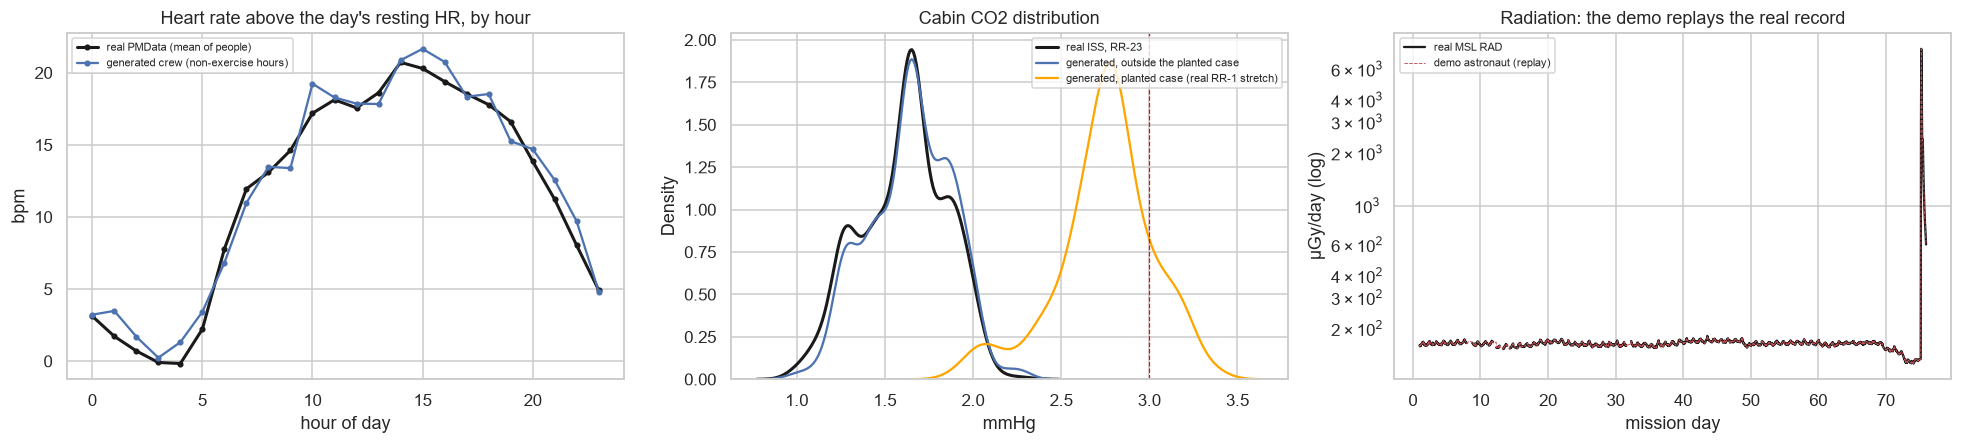

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
real_prof = params["hr_profile"]
gen_prof = tel.assign(rel=tel.heart_rate - tel.groupby(["astronaut_id", "mission_day"]).heart_rate.transform("min"))
rest = daily.set_index(["astronaut_id", "mission_day"]).resting_hr
t2 = tel[tel.exercise_type == "none"].copy()
t2["rel"] = t2.heart_rate - rest.reindex(pd.MultiIndex.from_frame(t2[["astronaut_id", "mission_day"]])).to_numpy()
axes[0].plot(range(24), real_prof, color="k", lw=2, marker="o", ms=3, label="real PMData (mean of people)")
axes[0].plot(t2.groupby("hour").rel.mean(), color="#4c72b0", marker="o", ms=3, label="generated crew (non-exercise hours)")
axes[0].set(title="Heart rate above the day's resting HR, by hour", xlabel="hour of day", ylabel="bpm"); axes[0].legend(fontsize=7)
cabin = pd.read_parquet(PROCESSED / "iss_cabin.parquet")
real_co2 = cabin.loc[cabin.mission == "RR-23", "co2_mmhg"].dropna()
quiet = one[(one.mission_day < 22) | (one.mission_day > 36)].cabin_co2_mmhg
sns.kdeplot(real_co2, ax=axes[1], color="k", lw=2, label="real ISS, RR-23"); sns.kdeplot(quiet, ax=axes[1], color="#4c72b0", label="generated, outside the planted case")
sns.kdeplot(one[one.mission_day.between(24, 33)].cabin_co2_mmhg, ax=axes[1], color="orange", label="generated, planted case (real RR-1 stretch)")
axes[1].axvline(3.0, color="red", ls="--", lw=0.8); axes[1].set(title="Cabin CO2 distribution", xlabel="mmHg"); axes[1].legend(fontsize=7)
mars = pd.read_parquet(PROCESSED / "msl_rad_hourly.parquet").set_index("hour").dose_e
window = mars.loc[demo["mission"]["radiation_replay"]["from"]: demo["mission"]["radiation_replay"]["to"]]
axes[2].plot(np.arange(len(window)) / 24 + 1, window.to_numpy(), color="k", lw=1.5, label="real MSL RAD")
axes[2].plot(np.arange(len(one)) / 24 + 1, one.radiation_ugy_per_day.to_numpy(), color="#c44e52", lw=0.6, ls="--", label="demo astronaut (replay)")
axes[2].set(yscale="log", title="Radiation: the demo replays the real record", xlabel="mission day", ylabel="µGy/day (log)"); axes[2].legend(fontsize=7)
savefig("08_generated_vs_real_hourly");
print("CO2 outside the planted case: generated mean %.2f mmHg vs real RR-23 %.2f | KS %.2f" % (quiet.mean(), real_co2.mean(), stats.ks_2samp(real_co2, quiet).statistic))
have = window.notna().to_numpy()
print("radiation replay equals the real hourly record on all %d hours that have data: %s; %d hours without data were filled with the previous day's median" % (
    have.sum(), bool(np.allclose(window.to_numpy()[have], one.radiation_ugy_per_day.to_numpy()[have], atol=0.06)), (~have).sum()))
mission_msv = one.radiation_msv.sum()
print("75-day mission dose in the demo: %.1f mSv (%.2f mSv/day)" % (mission_msv, mission_msv / 75))

In [9]:
# Published ranges for the signals that exist in no real dataset (simulated, v0 simulator): check they sit inside normal limits at rest.
rest_rows = tel[(tel.is_asleep == 0) & (tel.exercise_type == "none")]
ranges = pd.DataFrame({"generated median": rest_rows[["systolic_bp", "diastolic_bp", "spo2", "core_temp", "resp_rate"]].median(),
                       "generated 1st-99th percentile": rest_rows[["systolic_bp", "diastolic_bp", "spo2", "core_temp", "resp_rate"]].quantile([.01, .99]).round(1).T.apply(lambda r: f"{r[0.01]} - {r[0.99]}", axis=1),
                       "normal adult range (published)": ["90 - 120 mmHg", "60 - 80 mmHg", "95 - 100 %", "36.1 - 37.2 C", "12 - 20 /min"]})
g = daily.blood_glucose_mg_dl
ranges.loc["blood_glucose_mg_dl (fasting)"] = [g.median(), f"{g.quantile(.01)} - {g.quantile(.99)}", "70 - 99 mg/dL"]
ranges.round(1)

,generated median,generated 1st-99th percentile,normal adult range (published)
systolic_bp,119.0,98.7 - 133.2,90 - 120 mmHg
diastolic_bp,74.0,61.2 - 83.8,60 - 80 mmHg
spo2,98.1,96.8 - 99.5,95 - 100 %
core_temp,37.1,36.6 - 37.6,36.1 - 37.2 C
resp_rate,15.8,11.4 - 18.6,12 - 20 /min
blood_glucose_mg_dl (fasting),85.0,72.0 - 97.04000000000002,70 - 99 mg/dL


In [10]:
v0_dir = ROOT / "data" / "demo_v0"
if not v0_dir.exists():                      # keep the purely simulated v0 crew for the baseline comparison in notebook 09
    shutil.copytree(ROOT / "data" / "demo", v0_dir)
crew.write_demo(demo)
print(sorted(p.name for p in (ROOT / "data" / "demo").iterdir()))
print(json.dumps(demo["sources"]["radiation_ugy_per_day"]), json.dumps(demo["sources"]["resting_hr"]))

['api_snapshots', 'crew.json', 'daily.csv', 'eye_exams', 'eye_exams.json', 'planted_cases.json', 'sources.json', 'telemetry.csv']
{"kind": "real", "dataset": "NASA/JPL MSL RAD (Curiosity), replayed"} {"kind": "simulated", "calibrated_on": "PMData"}


## Decision

**The demo astronaut** (`data/demo/`): one fictional astronaut alone on a 75-day Mars surface mission (team decision of 14 Nov 2026: the app is personal,
so all four planted cases are on the same person, at different times). Hourly telemetry keeps the v0 column layout (so the API shape stays valid),
plus a daily table (`daily.csv`: resting HR, sleep, fatigue, mood, stress, headache, fasting glucose).

**How each signal is made, and how well it matches the real data**

| signal | method | real | generated |
|---|---|---|---|
| resting HR | AR(1) around a personal mean | between people SD 6.8, within 2.1 bpm, lag-1 0.85 | 6.7, 2.0, 0.83 |
| sleep minutes | personal mean + resampled real night residuals | within-person SD 66 min, lag-1 0.03 | 64 min, −0.01 |
| fatigue, mood, stress (1–5) | Markov chain with a real person's day-to-day transition matrix | within-person SD 0.53–0.67 | 0.59–0.72 |
| hourly heart rate | day's resting HR + real hour-of-day profile + scatter (SD 6.9 bpm, from real night hours; awake scatter is tied to activity level) | profile from PMData | same profile by construction |
| cabin CO2 | block bootstrap of real ISS mission RR-23 | mean 1.61 mmHg | within 0.05 mmHg (printed above) |
| radiation | **replay of real MSL RAD**, 7 Mar – 20 May 2024 | — | equal on every hour that has data (count printed above); empty hours filled |
| BP, SpO2, temperature, respiration, HRV, reaction time, fluids, glucose | v0 simulator, published normal ranges | — | simulated only |

All within-person distributions are within a KS distance of 0.06 of the real ones.

**The 4 planted cases** (ground truth in `planted_cases.json`, never read by the engine):

| # | case | who | mission days | what was planted | expected detector |
|---|---|---|---|---|---|
| 1 | Cabin CO2 + headache | Nadia Farouk (the cabin and her) | 24–33, headaches from day 27 | the highest real 10-day CO2 stretch of RR-1 (2014) spliced in; headache reports, fatigue ≤ 2 | environmental gate |
| 2 | Slow drift (illness onset) | Nadia Farouk | 40–49 ramp, held to 54, then resolved | resting HR +6 bpm (2.5 personal SD), sleep −60 min (1.2 SD), fatigue 1 point worse | CUSUM |
| 3 | Odd combination | Nadia Farouk | 62–68 | mood −1 point, stress −1 point, sleep −55 min (1.3 SD) | Isolation Forest |
| 4 | Solar storm | Nadia Farouk (the habitat) | 75, from 05:00 (under way "now") | the real May 2024 storm, unscaled | SPE alarm |

The storm is placed on the last day so that the app's "now" shows the alarm that matters most; the replay slider shows the other three.

**Rejected**
- **Copying real PMData people as crew.** It would present real individuals' data as astronauts; the generator copies statistics, not people.
- **A Gaussian model for sleep and self-reports.** Real sleep is skewed (occasional very short nights) and the reports are 5-level integers; resampling and Markov chains keep both.
- **Building the whole cabin series from an early ISS mission** (team decision): the gate would be active most of the time.
- **Planting RR-7's worst stretch** (first attempt): it reaches 6.8 mmHg, which trips the 6 mmHg hard limit for 32 hours and turns a chronic-CO2 case into an emergency. RR-1's stretch sits just over the 7-day limit, which is the case the team described.

**Known limits**
- PMData are healthy athletes on Earth. Microgravity changes resting HR, sleep and mood in ways this crew does not show.
- Signals are generated independently of each other, as they are in PMData (resting HR vs fatigue r = −0.02, notebook 01). A real illness would couple them; only the planted cases do.
- The self-reports are slightly more variable than the real ones (SD 0.59–0.72 vs 0.53–0.67).
- Simulated blood pressure runs a little high at rest (median 123/74 mmHg) because it comes unchanged from the v0 simulator.
- The planted sizes were chosen by us. The odd-combination case shifts mood and stress by a full scale point, which is 1.6–1.9 personal SDs for this person: subtle, but more than the ±1.5 SD the plan sketched.
- Radiation is Curiosity's measurement on the Mars surface. It is real, but it is not a dosimeter worn by a person.